In [1]:
import numpy as np
matrix  = np.array([[1,2,3], [4,5,6], [7,8,9]])
mask = np.array([[1],[2]])
matrix[mask]

array([[[4, 5, 6]],

       [[7, 8, 9]]])

In [2]:
from utils.ConeGraphProducer import ConeGraphProducer
import torch

# Produce the graphs. The call to JetGraphProducer will produce the graphs and
# save them in the specified directory if it is not already present.

tau3mu_cone_fully = ConeGraphProducer(
        "data/signal", # Path to the directory containing the root files to be processed
        "tau3mu_cone_fully", # Name to be given to the produced dataset (or the name of the dataset if it is already present)
        cone_size=0.7, # Size of cone around jet to consider pf_cand
        n_cones=1, # Number of cones/ graphs to build per event. Should be 1 or 3
        edge_connection_mode="fully", #mode to connect nodes, should be in ["r_threshold", "knn", "fully"]
        delta_r_threshold=None, # Threshold for the deltaR distance between constituents to be considered connected
        k_knn=None,
        max_events_to_process=None, # Maximum number of events to process (set to None to process all events)
        save_edge_attributes=True, # Whether to save the edge attributes (pairwise invariant masses, Cambridge-Aachen and kt distances)
        save_event_number=False, # Whether to save the event number in the graph
        weights=None, # Weights to be applied to the graphs (None, "xsec")
        save_fitted_tau_idx=False, # Whether to save the jet index
        label=1., # Label to add to the graph for supervised learning
        verbose=True, # Whether to print the progress of the processing
        use_displacement=False,
    )

tau3mu_cone_knn = ConeGraphProducer(
        "data/signal", # Path to the directory containing the root files to be processed
        "tau3mu_cone_knn", # Name to be given to the produced dataset (or the name of the dataset if it is already present)
        cone_size=0.7, # Size of cone around jet to consider pf_cand
        n_cones=1, # Number of cones/ graphs to build per event. Should be 1 or 3
        edge_connection_mode="knn", #mode to connect nodes, should be in ["r_threshold", "knn", "fully"]
        delta_r_threshold=None, # Threshold for the deltaR distance between constituents to be considered connected
        k_knn=3,
        max_events_to_process=None, # Maximum number of events to process (set to None to process all events)
        save_edge_attributes=True, # Whether to save the edge attributes (pairwise invariant masses, Cambridge-Aachen and kt distances)
        save_event_number=False, # Whether to save the event number in the graph
        weights=None, # Weights to be applied to the graphs (None, "xsec")
        save_fitted_tau_idx=False, # Whether to save the jet index
        label=1., # Label to add to the graph for supervised learning
        verbose=True, # Whether to print the progress of the processing
        use_displacement=False,
    )

tau3mu_cone_r_threshold = ConeGraphProducer(
        "data/signal", # Path to the directory containing the root files to be processed
        "tau3mu_cone_r_theshold", # Name to be given to the produced dataset (or the name of the dataset if it is already present)
        cone_size=0.7, # Size of cone around jet to consider pf_cand
        n_cones=1, # Number of cones/ graphs to build per event. Should be 1 or 3
        edge_connection_mode="r_threshold", #mode to connect nodes, should be in ["r_threshold", "knn", "fully"]
        delta_r_threshold=0.3, # Threshold for the deltaR distance between constituents to be considered connected
        k_knn=None,
        max_events_to_process=None, # Maximum number of events to process (set to None to process all events)
        save_edge_attributes=True, # Whether to save the edge attributes (pairwise invariant masses, Cambridge-Aachen and kt distances)
        save_event_number=False, # Whether to save the event number in the graph
        weights=None, # Weights to be applied to the graphs (None, "xsec")
        save_fitted_tau_idx=False, # Whether to save the jet index
        label=1., # Label to add to the graph for supervised learning
        verbose=True, # Whether to print the progress of the processing
        use_displacement=False,
    )

Processing...


Processing data/signal/tau3muNANO_mc_2022EE_SV.root


 30%|██▉       | 87/293 [00:06<00:13, 15.13it/s]/work/kfuss/SVJ_GNN/utils/ConeGraphProducer.py:281: RuntimeWarning: divide by zero encountered in log
  pair_masses = np.clip(np.nan_to_num(np.log(pair_masses)), a_max=1e5, a_min=-1e5)
/work/kfuss/SVJ_GNN/utils/ConeGraphProducer.py:281: RuntimeWarning: invalid value encountered in log
  pair_masses = np.clip(np.nan_to_num(np.log(pair_masses)), a_max=1e5, a_min=-1e5)
100%|██████████| 293/293 [00:26<00:00, 11.17it/s]
Done!
/work/kfuss/SVJ_GNN/utils/ConeGraphProducer.py:123: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be exec

Processing data/signal/tau3muNANO_mc_2022EE_SV.root


100%|██████████| 293/293 [00:05<00:00, 52.47it/s]
Done!
Processing...


Processing data/signal/tau3muNANO_mc_2022EE_SV.root


100%|██████████| 293/293 [00:06<00:00, 42.09it/s]
Done!


In [3]:
from utils.PlotGraph import plot_graph

293
Data(x=[36, 5], edge_index=[2, 1260], edge_attr=[1260, 3], y=[1], pos=[36], num_node_features=[1], w=[1], num_nodes=36)
tensor([[ 0,  0,  0,  ..., 35, 35, 35],
        [ 1,  2,  3,  ..., 32, 33, 34]])


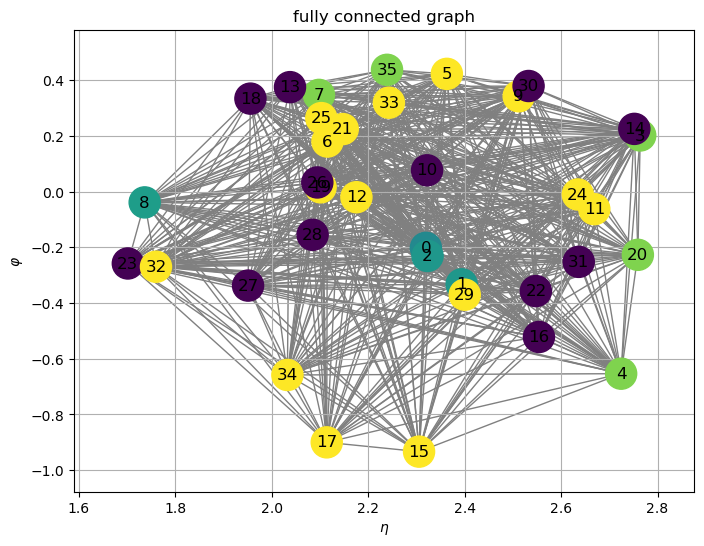

In [4]:
print(len(tau3mu_cone_fully))
print(tau3mu_cone_fully[0])
print(tau3mu_cone_fully[0].edge_index)
plot_graph(tau3mu_cone_fully[0], "fully connected graph")

293
Data(x=[36, 5], edge_index=[2, 138], edge_attr=[138, 3], y=[1], pos=[36], num_node_features=[1], w=[1], num_nodes=36)
tensor([[35, 16,  7, 28, 30, 27, 16, 20, 31, 20, 23,  3, 14,  5, 32, 15, 25,  8,
         16,  7, 31, 17, 24, 16, 19, 21,  9,  0,  9, 35, 24, 25, 32, 18, 33,  2,
         14, 29, 22,  5, 14, 13, 35, 25, 23, 15,  3, 12,  4,  1,  4, 26, 10, 13,
         33, 17,  9, 12, 22, 12, 12, 33,  1, 10, 24, 27, 28, 10, 11, 29,  0, 22,
         21,  6, 14,  7, 18, 21, 34, 33,  1,  2,  8, 19, 25, 11, 13,  6,  7,  3,
         19, 27, 27, 19, 11, 20, 31, 21,  6, 31, 17, 19, 22, 25, 16, 26, 31, 22,
         15, 29,  7, 18, 34, 30,  0, 22, 30, 28,  8, 32,  5, 29, 26,  1, 24,  6,
         26,  4, 34,  7, 11,  2, 28, 23,  5, 29, 26, 21],
        [33, 29, 35, 12,  9, 34, 22, 22, 22, 31, 27, 24, 24, 30, 23, 16, 18, 32,
         15, 21, 24, 16,  3, 17,  6, 25,  5,  2, 14,  5, 14, 13, 27,  7, 35, 29,
          3, 22, 16,  9, 30,  7,  7,  6,  8, 34, 14, 26, 22, 22, 31,  6, 19, 18,
         2

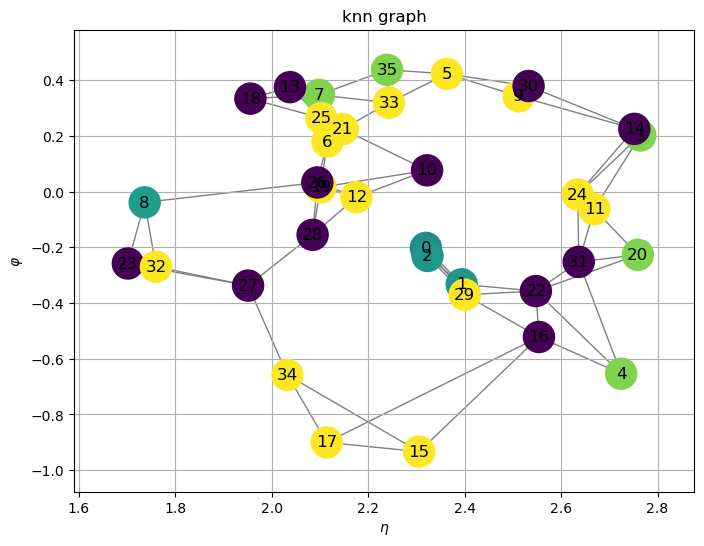

In [5]:
print(len(tau3mu_cone_knn))
print(tau3mu_cone_knn[0])
print(tau3mu_cone_knn[0].edge_index)
plot_graph(tau3mu_cone_knn[0], "knn graph")

293
Data(x=[36, 5], edge_index=[2, 214], edge_attr=[214, 3], y=[1], pos=[36], num_node_features=[1], w=[1], num_nodes=36)
tensor([[ 0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,
          2,  3,  3,  3,  3,  3,  4,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,
          6,  6,  6,  6,  6,  6,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  9,  9,
          9,  9,  9,  9, 10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11, 11, 12,
         12, 12, 12, 12, 12, 12, 12, 12, 13, 13, 13, 13, 13, 13, 13, 14, 14, 14,
         14, 14, 15, 16, 16, 16, 16, 16, 17, 17, 18, 18, 18, 18, 18, 18, 19, 19,
         19, 19, 19, 19, 19, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 21, 21, 21,
         21, 21, 21, 22, 22, 22, 22, 22, 22, 22, 23, 23, 23, 24, 24, 24, 24, 24,
         25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 25, 26, 26, 26, 26, 26, 26, 26,
         27, 27, 27, 28, 28, 28, 28, 28, 28, 29, 29, 29, 29, 29, 29, 30, 30, 30,
         30, 30, 30, 31, 31, 31, 31, 31, 31, 31, 32, 32, 32, 33, 33,

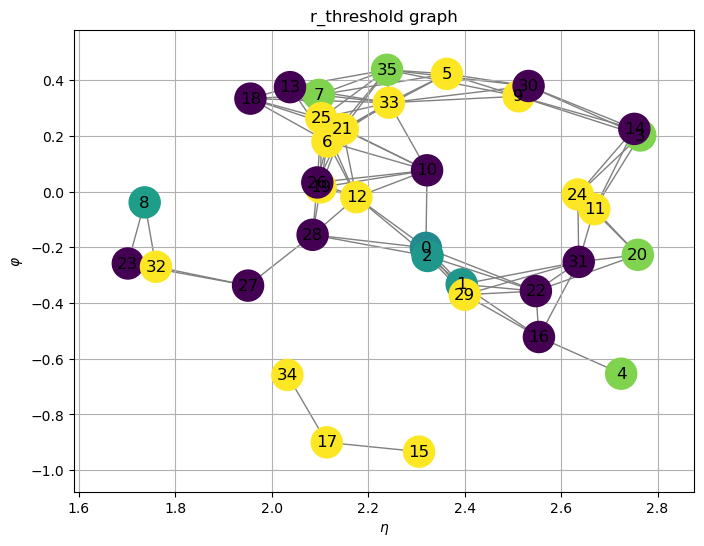

In [6]:
print(len(tau3mu_cone_r_threshold))
print(tau3mu_cone_r_threshold[0])
print(tau3mu_cone_r_threshold[0].edge_index)
plot_graph(tau3mu_cone_r_threshold[0], "r_threshold graph")

In [7]:
import uproot

f = uproot.open("data/signal/tau3muNANO_mc_2022EE_SV.root")
df = f["Events"].arrays(["TauTo3Mu_charge", "nTauTo3Mu"])
# df["TauTo3Mu_charge"]
f["Events"].keys()

['run',
 'luminosityBlock',
 'event',
 'bunchCrossing',
 'orbitNumber',
 'nTauTo3Mu',
 'TauTo3Mu_charge',
 'TauTo3Mu_diMuVtxFit_toVeto',
 'TauTo3Mu_fired_Tau3Mu_Mu7_Mu1_TkMu1_IsoTau15',
 'TauTo3Mu_fired_Tau3Mu_Mu7_Mu1_TkMu1_IsoTau15_Charge1',
 'TauTo3Mu_mu1_charge',
 'TauTo3Mu_mu1_fired_DoubleMu4_3_LowMass',
 'TauTo3Mu_mu1_fired_Tau3Mu_Mu7_Mu1_TkMu1_IsoTau15',
 'TauTo3Mu_mu1_fired_Tau3Mu_Mu7_Mu1_TkMu1_IsoTau15_Charge1',
 'TauTo3Mu_mu1_idx',
 'TauTo3Mu_mu1_trackQuality',
 'TauTo3Mu_mu2_charge',
 'TauTo3Mu_mu2_fired_DoubleMu4_3_LowMass',
 'TauTo3Mu_mu2_fired_Tau3Mu_Mu7_Mu1_TkMu1_IsoTau15',
 'TauTo3Mu_mu2_fired_Tau3Mu_Mu7_Mu1_TkMu1_IsoTau15_Charge1',
 'TauTo3Mu_mu2_idx',
 'TauTo3Mu_mu2_trackQuality',
 'TauTo3Mu_mu3_charge',
 'TauTo3Mu_mu3_fired_DoubleMu4_3_LowMass',
 'TauTo3Mu_mu3_fired_Tau3Mu_Mu7_Mu1_TkMu1_IsoTau15',
 'TauTo3Mu_mu3_fired_Tau3Mu_Mu7_Mu1_TkMu1_IsoTau15_Charge1',
 'TauTo3Mu_mu3_idx',
 'TauTo3Mu_mu3_trackQuality',
 'TauTo3Mu_vtx_isValid',
 'TauTo3Mu_CosAlpha2D_LxyP3mu',
 'Ta